# Tutorial 02 — Street Network Analysis

This notebook demonstrates how to:

1. Build a **primal street network** with `get_street_network()`.
2. Inspect node and edge GeoDataFrames.
3. Compute **graph centrality** metrics.
4. Visualise the results with Urbanity's built-in **static** and **interactive** plotters.

The new data access workflow introduced in v0.2 automatically downloads the smallest available OSM extract that covers your study boundary — no manual link or `.osm.pbf` path required.

In [1]:
from urbanity import Map
from urbanity.visualisation import (
    plot_street_network,
    plot_network_centrality,
    plot_node_attribute,
)
import geopandas as gpd
import matplotlib.pyplot as plt

## 1  Setup — Study Area

We use the bundled **Tanjong Pagar** (Singapore) neighbourhood boundary. Swap this path for any GeoJSON or Shapefile covering your city of interest.

In [2]:
m = Map(country='Singapore')
m.add_polygon_boundary('data/tanjong_pagar_singapore.geojson',
                        layer_name='Tanjong Pagar')

print("Boundary set:", m.polygon_bounds.geometry.iloc[0].geom_type)

Boundary set: Polygon


## 2  Building the Street Network

`get_street_network()` accepts no mandatory arguments when a `polygon_bounds` is already set.  
Urbanity automatically:

- queries **Geofabrik** and **BBBike** to find the smallest available OSM extract;
- downloads and caches it in `./data/`;
- clips it to your polygon and builds a simplified NetworkX `MultiDiGraph`.

Optional `*_attr` flags can enrich nodes with buildings, population, POIs, or street view imagery.

In [3]:
G, nodes, edges = m.get_street_network(
    bandwidth=100,         # buffer distance (m) to capture context beyond boundary
    network_type='driving',
    graph_attr=True,       # include betweenness, closeness, degree centrality
    building_attr=False,
    pop_attr=False,
    poi_attr=False,
)

print(f"Nodes: {len(nodes):,}  |  Edges: {len(edges):,}")

BBBike index built: 238 cities
Best extract: Singapore (bbbike) — 37.3 MB
  Progress: 100.0% (37.3/37.3 MB)
Download complete: ./data/bbbike_Singapore.osm.pbf
Data extracted successfully. Proceeding to construct street network.
Network constructed. Time taken: 108.
Topologic/metric attributes computed. Time taken: 110.
Total elapsed time --- 110 seconds ---
Nodes: 8,051  |  Edges: 20,314


## 3  Inspecting the Output GeoDataFrames

In [4]:
nodes.head()

,intersection_id,osmid,x,y,geometry,intersection_degree,intersection_clustering,inter_section_weighted_clustering,Closeness Centrality,Betweenness Centrality,Eigenvector Centrality,Katz Centrality,PageRank
0,0,4748500344,103.830063,1.306018,POINT (103.83006 1.30602),3,0.0,0.0,0.027,0.256,0.274,0.026,0.0
1,1,6427627507,103.830109,1.305992,POINT (103.83011 1.30599),3,0.0,0.0,0.027,0.253,0.271,0.025,0.0
2,2,74355703,103.839287,1.313432,POINT (103.83929 1.31343),4,0.0,0.0,0.027,0.252,0.268,0.023,0.0
3,3,2666453628,103.839493,1.313585,POINT (103.83949 1.31359),3,0.0,0.0,0.027,0.252,0.257,0.022,0.0
4,4,3181999572,103.839882,1.313886,POINT (103.83988 1.31389),3,0.0,0.0,0.027,0.252,0.255,0.021,0.0


In [5]:
edges.head()

,u,v,length,geometry,edge_id
0,4748500344,6427627507,5.892,"LINESTRING (103.83006 1.30602, 103.83011 1.30599)",0
1,4748500344,6330272156,19.037,"LINESTRING (103.82991 1.3061, 103.83006 1.30602)",1
2,4748500344,4748500339,40.635,"LINESTRING (103.83006 1.30602, 103.83008 1.306...",2
3,6427627507,4748500344,5.892,"LINESTRING (103.83006 1.30602, 103.83011 1.30599)",3
4,6427627507,4748500346,20.061,"LINESTRING (103.83011 1.30599, 103.83015 1.305...",4


In [6]:
# Quick column summary
print("Node columns:",  list(nodes.columns))
print("Edge columns:",  list(edges.columns))

Node columns: ['intersection_id', 'osmid', 'x', 'y', 'geometry', 'intersection_degree', 'intersection_clustering', 'inter_section_weighted_clustering', 'Closeness Centrality', 'Betweenness Centrality', 'Eigenvector Centrality', 'Katz Centrality', 'PageRank']
Edge columns: ['u', 'v', 'length', 'geometry', 'edge_id']


## 4  Static Visualisation

`plot_street_network()` produces a high-quality matplotlib figure using a dark-mode theme by default.

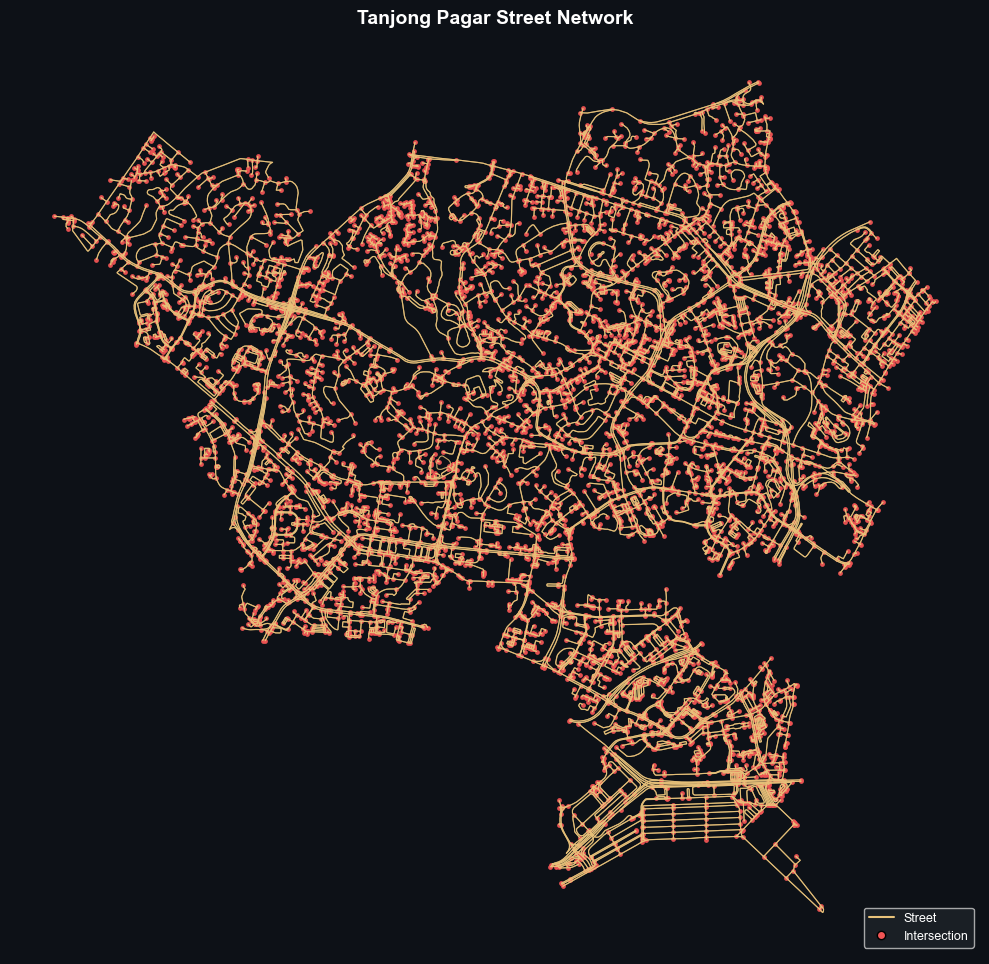

In [7]:
fig = plot_street_network(
    nodes, edges,
    title='Tanjong Pagar Street Network',
    dark_mode=True,
)
plt.show()

### 4a  Colour-code edges by length

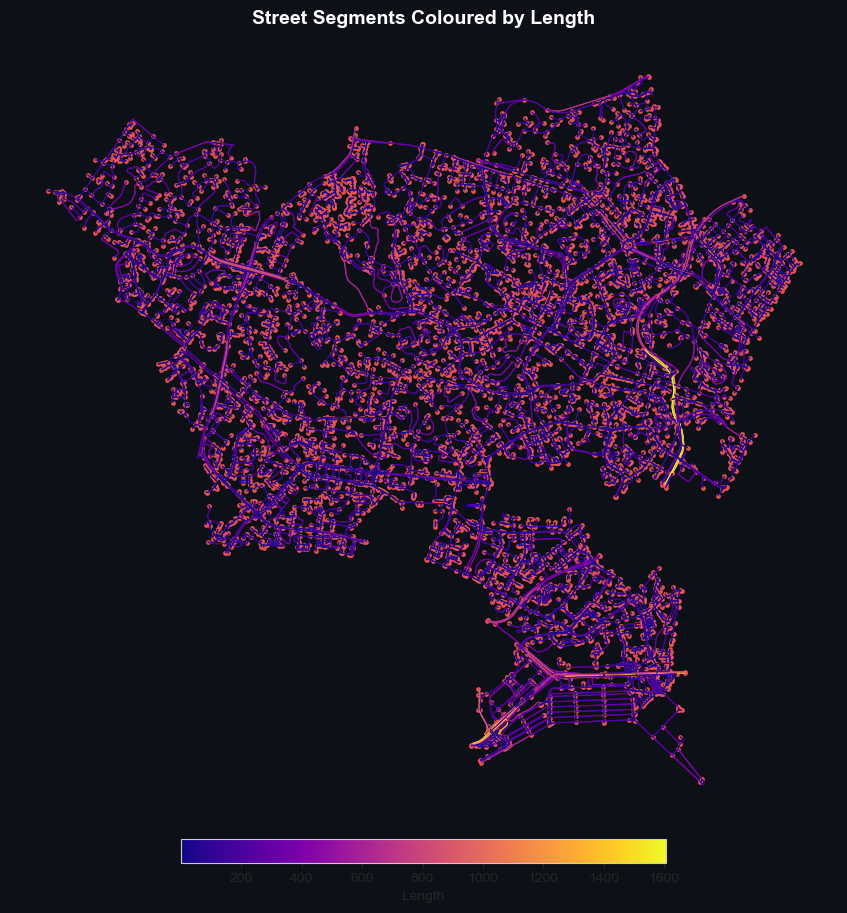

In [8]:
fig = plot_street_network(
    nodes, edges,
    colname='length',          # colour edges by street segment length (m)
    cmap='plasma',
    title='Street Segments Coloured by Length',
    dark_mode=True,
)
plt.show()

## 5  Network Centrality Visualisation

When `graph_attr=True` is set, `get_street_network` computes betweenness and closeness centrality and stores them in the node GeoDataFrame.  
`plot_network_centrality()` renders nodes sized and coloured proportionally to a chosen centrality column.

In [9]:
# List available centrality columns
centrality_cols = [c for c in nodes.columns
                   if any(k in c for k in ['betweenness','closeness','degree','pagerank'])]
print("Centrality columns:", centrality_cols)

Centrality columns: ['intersection_degree']


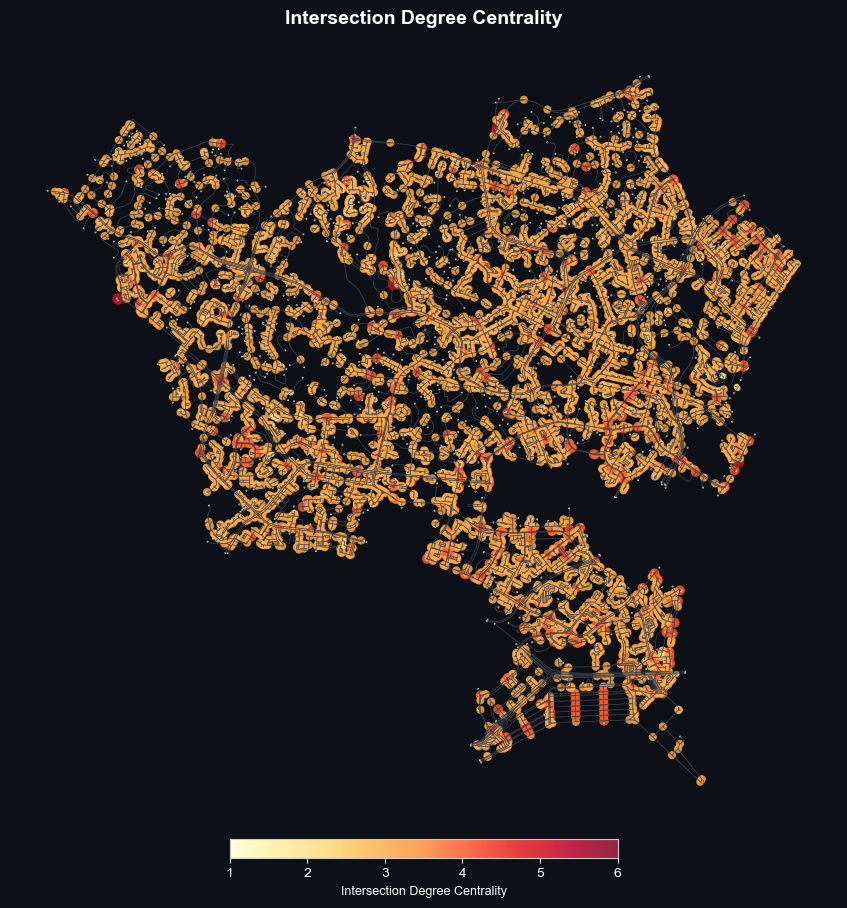

In [10]:
if centrality_cols:
    fig = plot_network_centrality(
        nodes, edges,
        centrality_col=centrality_cols[0],
        title=f'{centrality_cols[0].replace("_"," ").title()} Centrality',
        dark_mode=True,
    )
    plt.show()
else:
    print("No centrality columns found. Re-run get_street_network with graph_attr=True.")

## 6  Interactive Visualisation with PyDeck

The `plot_graph()` function in `urbanity.visualisation` creates a 3-D interactive view that runs in Jupyter. Here we quickly demonstrate it on the street and intersection layers of the UrbanGraph objects dictionary.

In [11]:
from urbanity.visualisation import plot_graph
import geopandas as gpd

# Assemble a minimal `objects` dict for plot_graph
# (plot_graph is designed for the full UrbanGraph objects dict;
#  here we pass stub GeoDataFrames for the layers we don't have)
objects_stub = {
    'boundary':     m.polygon_bounds,
    'street':       edges,
    'intersection': nodes,
    'plot':         gpd.GeoDataFrame(geometry=[]),
    'building':     gpd.GeoDataFrame(geometry=[]),
}

plot_graph(objects_stub, connections={}, node_type='street')

{
  "initialViewState": {
    "bearing": 135,
    "height": 1000,
    "latitude": 1.3016853774343775,
    "longitude": 103.82306883816486,
    "pitch": 45,
    "width": 500,
    "zoom": 14
  },
  "layers": [
    {
      "@@type": "GeoJsonLayer",
      "data": [],
      "extruded": true,
      "getElevation": "@@=bid_height",
      "getFillColor": "@@=[255,255,255,50]",
      "getLineColor": "@@=[255,255,255,50]",
      "id": "f714c600-597b-4565-a82a-c676a5eb879f"
    },
    {
      "@@type": "GeoJsonLayer",
      "data": [],
      "getFillColor": "@@=[255,255,255,255]",
      "getLineColor": "@@=[255,255,255,255]",
      "id": "a2509932-0656-4b0d-abb9-838958799fd5",
      "lineWidthMinPixels": 2,
      "opacity": 1
    },
    {
      "@@type": "ScatterplotLayer",
      "data": [
        {
          "Betweenness Centrality": 0.256,
          "Closeness Centrality": 0.027,
          "Eigenvector Centrality": 0.274,
          "Katz Centrality": 0.026,
          "PageRank": 0.0,
          "geometry": {
            "coordinates": [
              103.83006286621094,
              1.306018352508545
            ],
            "type": "Point"
          },
          "inter_section_weighted_clustering": 0.0,
          "intersection_clustering": 0.0,
          "intersection_degree": 3,
          "intersection_id": 0,
          "osmid": 4748500344,
          "x": 103.83006286621094,
          "y": 1.306018352508545
        },
        {
          "Betweenness Centrality": 0.253,
          "Closeness Centrality": 0.027,
          "Eigenvector Centrality": 0.271,
          "Katz Centrality": 0.025,
          "PageRank": 0.0,
          "geometry": {
            "coordinates": [
              103.83010864257812,
              1.3059916496276855
            ],
            "type": "Point"
          },
          "inter_section_weighted_clustering": 0.0,
          "intersection_clustering": 0.0,
          "intersection_degree": 3,
          "intersection_id": 1,
          "osmid": 6427627507,
          "x": 103.83010864257812,
          "y": 1.3059916496276855
        },
        {
          "Betweenness Centrality": 0.252,
          "Closeness Centrality": 0.027,
          "Eigenvector Centrality": 0.268,
          "Katz Centrality": 0.023,
          "PageRank": 0.0,
          "geometry": {
            "coordinates": [
              103.83928680419922,
              1.313431739807129
            ],
            "type": "Point"
          },
          "inter_section_weighted_clustering": 0.0,
          "intersection_clustering": 0.0,
          "intersection_degree": 4,
          "intersection_id": 2,
          "osmid": 74355703,
          "x": 103.83928680419922,
          "y": 1.313431739807129
        },
        {
          "Betweenness Centrality": 0.252,
          "Closeness Centrality": 0.027,
          "Eigenvector Centrality": 0.257,
          "Katz Centrality": 0.022,
          "PageRank": 0.0,
          "geometry": {
            "coordinates": [
              103.83949279785156,
              1.3135850429534912
            ],
            "type": "Point"
          },
          "inter_section_weighted_clustering": 0.0,
          "intersection_clustering": 0.0,
          "intersection_degree": 3,
          "intersection_id": 3,
          "osmid": 2666453628,
          "x": 103.83949279785156,
          "y": 1.3135850429534912
        },
        {
          "Betweenness Centrality": 0.252,
          "Closeness Centrality": 0.027,
          "Eigenvector Centrality": 0.255,
          "Katz Centrality": 0.021,
          "PageRank": 0.0,
          "geometry": {
            "coordinates": [
              103.83988189697266,
              1.3138855695724487
            ],
            "type": "Point"
          },
          "inter_section_weighted_clustering": 0.0,
          "intersection_clustering": 0.0,
          "intersection_degree": 3,
          "intersection_id": 4,
          "osmid": 3181999572,
          "x": 103.83988189697266,
          "y": 1

## 7  Saving the Network

Both GeoDataFrames can be persisted in any standard geospatial format:

In [ ]:
# nodes.to_file('output/tanjong_pagar_nodes.geojson', driver='GeoJSON')
# edges.to_file('output/tanjong_pagar_edges.geojson', driver='GeoJSON')
print("Uncomment the lines above to save the GeoDataFrames to disk.")

## Summary

| What | How |
|---|---|
| Build street network | `m.get_street_network()` — no OSM file needed |
| Static map | `plot_street_network(nodes, edges)` |
| Colour by attribute | `colname='length'` or any column |
| Centrality map | `plot_network_centrality(nodes, edges, centrality_col=...)` |
| Interactive 3-D view | `plot_graph(objects, connections)` |

Continue to **Tutorial 03** to build a full heterogeneous UrbanGraph.